In [2]:

# Step 1: Import Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

print("Libraries imported successfully!")


Libraries imported successfully!


In [3]:

# Step 2: Generate sample customer data
# This allows the notebook to run without downloading a dataset.

np.random.seed(42)

n = 300

data = pd.DataFrame({
    "CustomerID": range(1, n + 1),
    "Gender": np.random.choice(["Male", "Female"], n),
    "Age": np.random.randint(18, 70, n),
    "Annual Income (k$)": np.random.randint(15, 140, n),
    "Spending Score (1-100)": np.random.randint(1, 100, n)
})

data.head()


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,50,136,41
1,2,Female,18,24,64
2,3,Male,36,132,27
3,4,Male,19,83,63
4,5,Male,61,114,17


In [4]:

# Step 3: Explore dataset

print("Dataset Shape:", data.shape)
print("\nDataset Information:")
data.info()

print("\nStatistical Summary:")
display(data.describe())

print("\nMissing Values:")
print(data.isnull().sum())


Dataset Shape: (300, 5)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              300 non-null    int64 
 1   Gender                  300 non-null    object
 2   Age                     300 non-null    int64 
 3   Annual Income (k$)      300 non-null    int64 
 4   Spending Score (1-100)  300 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 11.8+ KB

Statistical Summary:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,300.000000,300.000000,300.000000,300.000000
mean,150.500000,44.490000,76.136667,50.483333
std,86.746758,14.779875,37.473799,29.409740
min,1.000000,18.000000,15.000000,1.000000
25%,75.750000,33.000000,43.000000,25.000000
50%,150.500000,45.000000,74.500000,52.000000
75%,225.250000,56.000000,109.000000,75.500000
max,300.000000,69.000000,139.000000,99.000000



Missing Values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


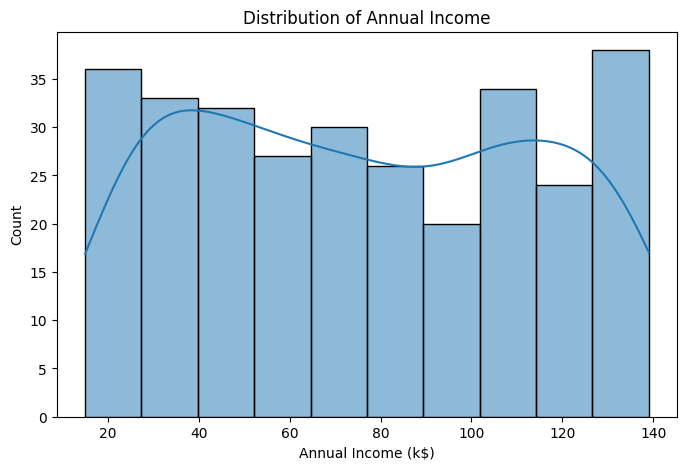

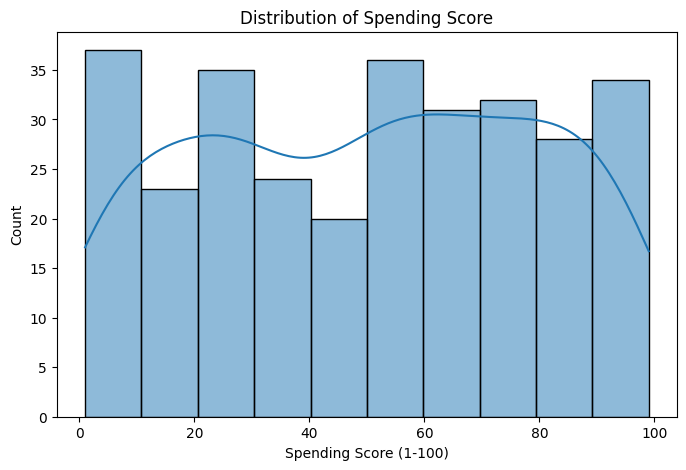

In [5]:

# Step 4: Visualize customer data

plt.figure(figsize=(8, 5))
sns.histplot(data["Annual Income (k$)"], kde=True)
plt.title("Distribution of Annual Income")
plt.show()

plt.figure(figsize=(8, 5))
sns.histplot(data["Spending Score (1-100)"], kde=True)
plt.title("Distribution of Spending Score")
plt.show()


In [6]:

# Step 5: Select features for clustering

X = data[["Annual Income (k$)", "Spending Score (1-100)"]]

X.head()


,Annual Income (k$),Spending Score (1-100)
0,136,41
1,24,64
2,132,27
3,83,63
4,114,17


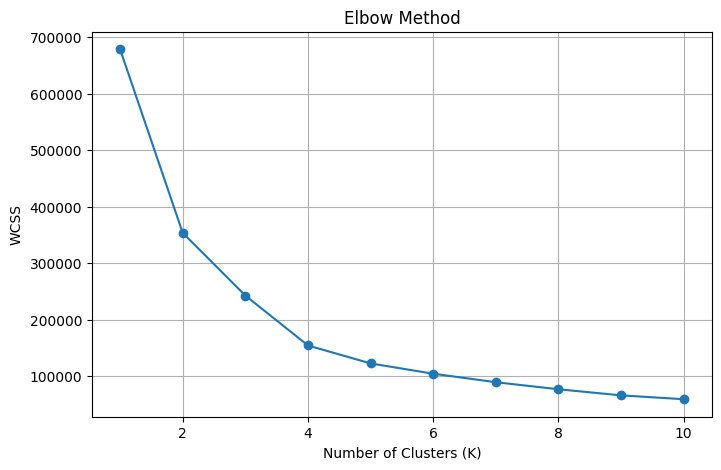

In [7]:

# Step 6: Elbow Method

wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.grid(True)
plt.show()


In [8]:

# Step 7: Train K-Means

kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

data["Cluster"] = kmeans.fit_predict(X)

print("Model trained successfully!")
print(data[["CustomerID", "Cluster"]].head())


Model trained successfully!
   CustomerID  Cluster
0           1        0
1           2        2
2           3        0
3           4        1
4           5        0


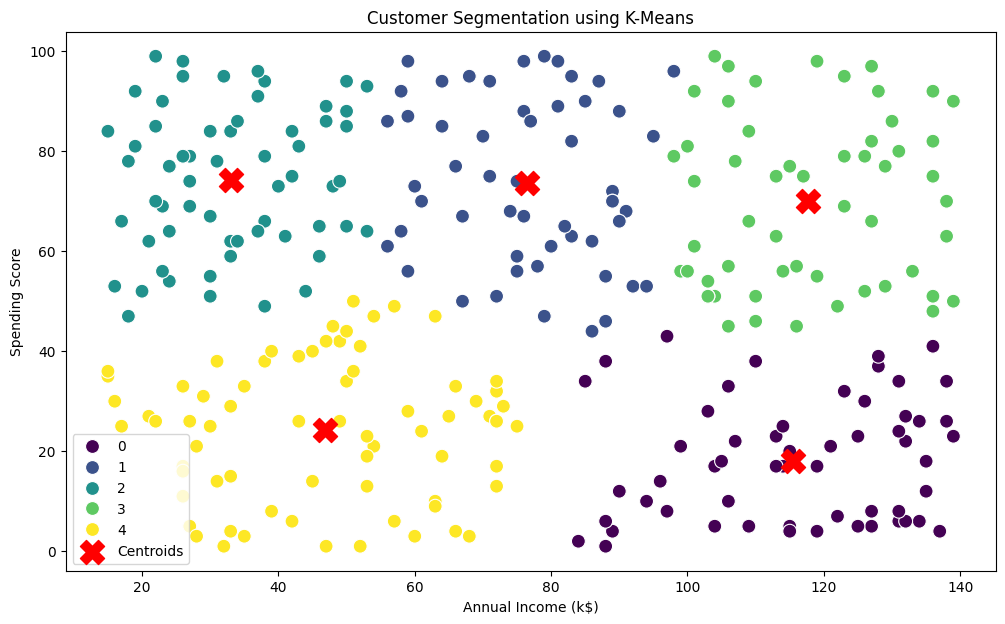

In [9]:

# Step 8: Customer Segmentation Visualization

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=data,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="viridis",
    s=100
)

centers = kmeans.cluster_centers_

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    s=300,
    c="red",
    marker="X",
    label="Centroids"
)

plt.title("Customer Segmentation using K-Means")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score")
plt.legend()
plt.show()


In [10]:

# Step 9: Cluster Analysis

cluster_analysis = data.groupby("Cluster").agg({
    "CustomerID": "count",
    "Age": "mean",
    "Annual Income (k$)": "mean",
    "Spending Score (1-100)": "mean"
}).round(2)

cluster_analysis.rename(
    columns={"CustomerID": "Number of Customers"},
    inplace=True
)

display(cluster_analysis)


,Number of Customers,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,,
0,59,44.19,115.54,18.05
1,54,45.28,76.50,73.69
2,60,45.12,33.05,74.30
3,56,43.89,117.66,70.04
4,71,44.08,46.77,24.24


In [11]:

# Step 10: Business Interpretation

for cluster in sorted(data["Cluster"].unique()):

    group = data[data["Cluster"] == cluster]

    income = group["Annual Income (k$)"].mean()
    spending = group["Spending Score (1-100)"].mean()

    print(f"\nCustomer Segment {cluster}")
    print(f"Average Annual Income: ${income:.2f}k")
    print(f"Average Spending Score: {spending:.2f}")

    if income > 70 and spending > 60:
        print("Strategy: Premium offers and loyalty rewards")

    elif income > 70 and spending < 40:
        print("Strategy: Personalized promotions to increase spending")

    elif income < 40 and spending > 60:
        print("Strategy: Affordable loyalty rewards")

    elif spending < 40:
        print("Strategy: Discounts and engagement campaigns")

    else:
        print("Strategy: Targeted offers and retention campaigns")



Customer Segment 0
Average Annual Income: $115.54k
Average Spending Score: 18.05
Strategy: Personalized promotions to increase spending

Customer Segment 1
Average Annual Income: $76.50k
Average Spending Score: 73.69
Strategy: Premium offers and loyalty rewards

Customer Segment 2
Average Annual Income: $33.05k
Average Spending Score: 74.30
Strategy: Affordable loyalty rewards

Customer Segment 3
Average Annual Income: $117.66k
Average Spending Score: 70.04
Strategy: Premium offers and loyalty rewards

Customer Segment 4
Average Annual Income: $46.77k
Average Spending Score: 24.24
Strategy: Discounts and engagement campaigns


In [13]:
# Step 11: Save and Download CSV file to your computer

from google.colab import files

# Save the dataframe containing the cluster assignments to a CSV file
data.to_csv("Customer_Segmentation_Results.csv", index=False)

# Download the file
files.download("Customer_Segmentation_Results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>